HEART DISEASE DATASET
Dataset Name: Heart Disease

Feature Shape: (303, 13)
Target Shape : (303, 1)

DATA CLEANING

Missing Values Before Cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Missing Values After Cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

Target Distribution:
num
0    164
1    139
Name: count, dtype: int64

Data Standardized Successfully

Training Samples: 242
Testing Samples : 61


2026-10-14 06:33:11.569502: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)



Architecture 1 (16)
Accuracy : 0.9016
Precision: 0.8929
Recall   : 0.8929
F1 Score : 0.8929

Classification Report
              precision    recall  f1-score   support

           0       0.91      0.91      0.91        33
           1       0.89      0.89      0.89        28

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61



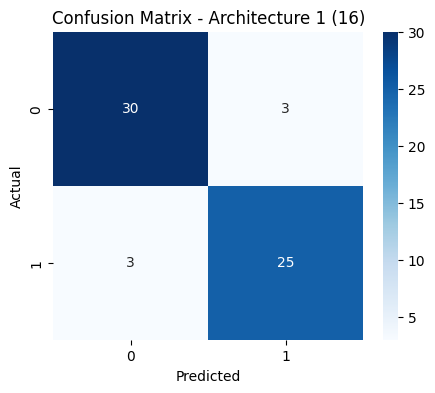


Architecture 2 (32-16)
Accuracy : 0.8361
Precision: 0.7812
Recall   : 0.8929
F1 Score : 0.8333

Classification Report
              precision    recall  f1-score   support

           0       0.90      0.79      0.84        33
           1       0.78      0.89      0.83        28

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61



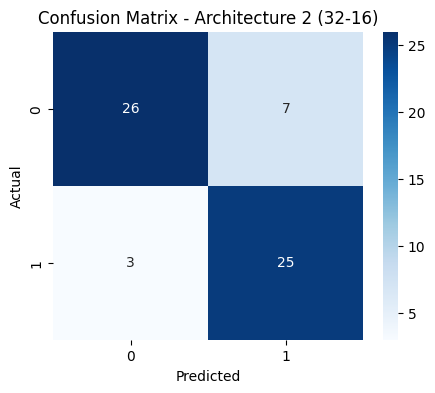


MODEL COMPARISON
             Architecture  Accuracy  Precision    Recall  F1 Score
0     Architecture 1 (16)  0.901639   0.892857  0.892857  0.892857
1  Architecture 2 (32-16)  0.836066   0.781250  0.892857  0.833333


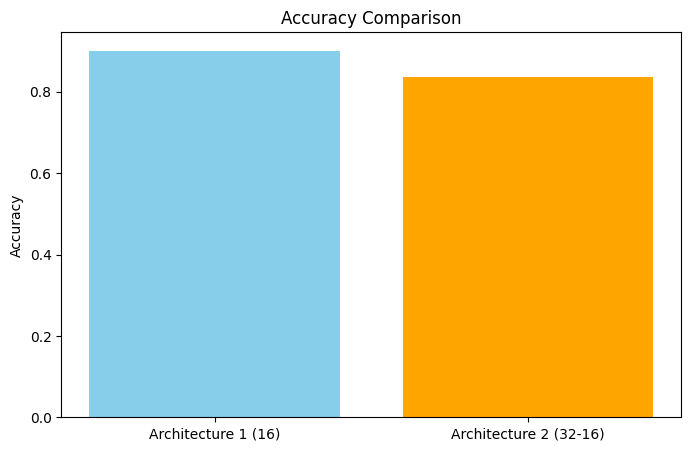

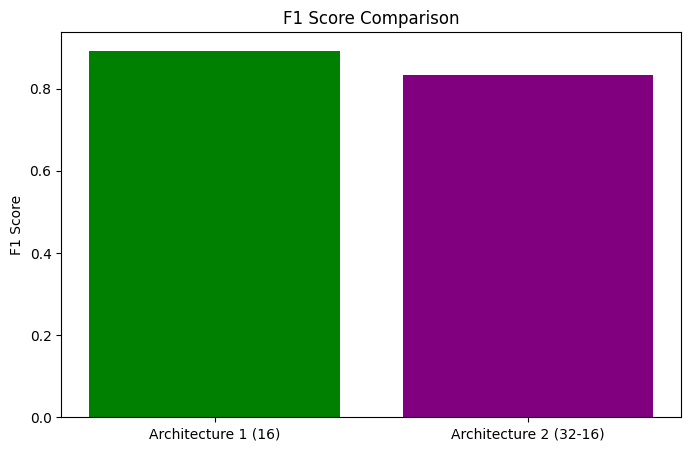

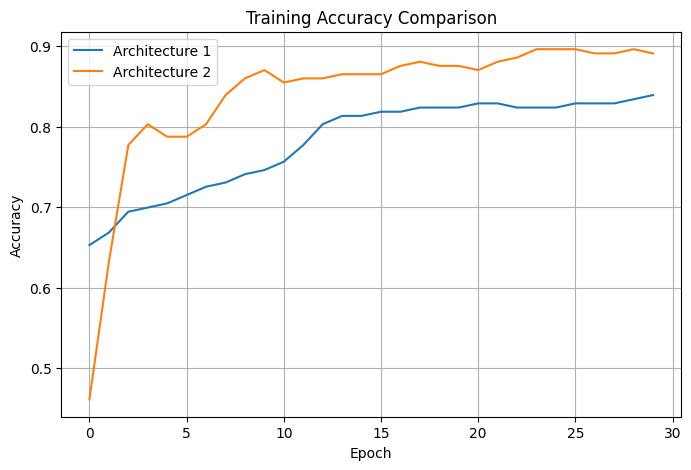

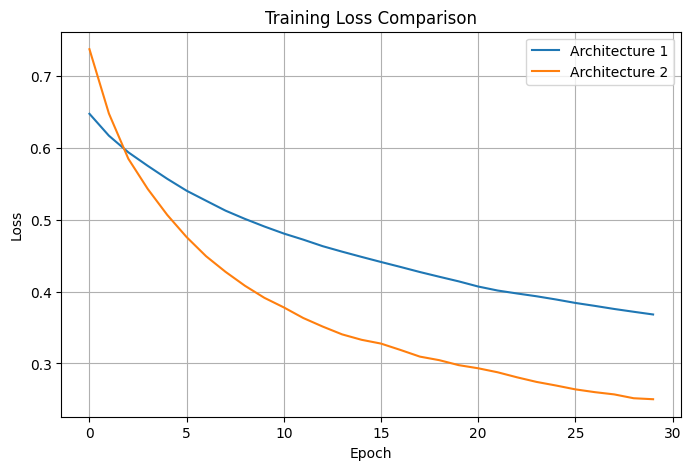


BEST PERFORMING MODEL
Architecture    Architecture 1 (16)
Accuracy                   0.901639
Precision                  0.892857
Recall                     0.892857
F1 Score                   0.892857
Name: 0, dtype: object

METRIC EXPLANATION


Accuracy
--------
Measures the percentage of correctly classified
instances.

Precision
---------
Measures how many predicted positive cases were
actually positive.

Recall
------
Measures how many actual positive cases were
correctly identified.

F1 Score
--------
Harmonic mean of Precision and Recall.
Provides a balanced evaluation metric.



CONCLUSION

The Heart Disease dataset was downloaded from the
UCI Machine Learning Repository and preprocessed
using median imputation and feature scaling.

Two Multi-Layer Perceptron architectures were
designed and compared:

Architecture 1:
Input → Dense(16) → Output

Architecture 2:
Input → Dense(32) → Dense(16) → Output

Both models were evaluated using:
• Accuracy
• Precision
• Recall
• F1 Score



In [1]:
# ==========================================================
# ASSIGNMENT 6
# Heart Disease Prediction using Two MLP Architectures
# Dataset: UCI Heart Disease Dataset
# ==========================================================

!pip install -q ucimlrepo tensorflow

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# ==========================================================
# 1. LOAD HEART DISEASE DATASET
# ==========================================================

print("="*60)
print("HEART DISEASE DATASET")
print("="*60)

heart = fetch_ucirepo(id=45)

print("Dataset Name:", heart.metadata["name"])

X = heart.data.features
y = heart.data.targets

print("\nFeature Shape:", X.shape)
print("Target Shape :", y.shape)

# ==========================================================
# 2. DATA CLEANING
# ==========================================================

print("\n" + "="*60)
print("DATA CLEANING")
print("="*60)

print("\nMissing Values Before Cleaning:")
print(X.isnull().sum())

imputer = SimpleImputer(strategy='median')

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("\nMissing Values After Cleaning:")
print(X.isnull().sum())

# ==========================================================
# 3. CONVERT TARGET TO BINARY
# ==========================================================

# 0 = No Heart Disease
# 1,2,3,4 = Heart Disease

y = (y.iloc[:, 0] > 0).astype(int)

print("\nTarget Distribution:")
print(y.value_counts())

# ==========================================================
# 4. FEATURE SCALING
# ==========================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nData Standardized Successfully")

# ==========================================================
# 5. TRAIN TEST SPLIT
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples :", len(X_test))

# ==========================================================
# 6. FUNCTION TO TRAIN AND EVALUATE MODELS
# ==========================================================

results = []

def evaluate_model(model, model_name):

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.20,
        epochs=30,
        batch_size=16,
        verbose=0
    )

    y_prob = model.predict(X_test, verbose=0)

    y_pred = (y_prob > 0.5).astype(int)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Architecture": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n" + "="*60)
    print(model_name)
    print("="*60)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")

    print("\nClassification Report")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

    return history

# ==========================================================
# 7. MLP ARCHITECTURE 1
# ==========================================================
# Input → Dense(16) → Output

model1 = Sequential([

    Dense(
        16,
        activation='relu',
        input_shape=(X_train.shape[1],)
    ),

    Dense(
        1,
        activation='sigmoid'
    )

])

model1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history1 = evaluate_model(
    model1,
    "Architecture 1 (16)"
)

# ==========================================================
# 8. MLP ARCHITECTURE 2
# ==========================================================
# Input → Dense(32) → Dense(16) → Output

model2 = Sequential([

    Dense(
        32,
        activation='relu',
        input_shape=(X_train.shape[1],)
    ),

    Dense(
        16,
        activation='relu'
    ),

    Dense(
        1,
        activation='sigmoid'
    )

])

model2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history2 = evaluate_model(
    model2,
    "Architecture 2 (32-16)"
)

# ==========================================================
# 9. COMPARISON TABLE
# ==========================================================

results_df = pd.DataFrame(results)

print("\n" + "="*60)
print("MODEL COMPARISON")
print("="*60)

print(results_df)

# ==========================================================
# 10. ACCURACY COMPARISON PLOT
# ==========================================================

plt.figure(figsize=(8,5))

plt.bar(
    results_df["Architecture"],
    results_df["Accuracy"],
    color=["skyblue", "orange"]
)

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")

plt.show()

# ==========================================================
# 11. F1 SCORE COMPARISON PLOT
# ==========================================================

plt.figure(figsize=(8,5))

plt.bar(
    results_df["Architecture"],
    results_df["F1 Score"],
    color=["green", "purple"]
)

plt.title("F1 Score Comparison")
plt.ylabel("F1 Score")

plt.show()

# ==========================================================
# 12. TRAINING ACCURACY COMPARISON
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(
    history1.history["accuracy"],
    label="Architecture 1"
)

plt.plot(
    history2.history["accuracy"],
    label="Architecture 2"
)

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

# ==========================================================
# 13. TRAINING LOSS COMPARISON
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(
    history1.history["loss"],
    label="Architecture 1"
)

plt.plot(
    history2.history["loss"],
    label="Architecture 2"
)

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

# ==========================================================
# 14. IDENTIFY BEST MODEL
# ==========================================================

best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("\n" + "="*60)
print("BEST PERFORMING MODEL")
print("="*60)

print(best_model)

# ==========================================================
# 15. METRIC EXPLANATION
# ==========================================================

print("\n" + "="*60)
print("METRIC EXPLANATION")
print("="*60)

print("""

Accuracy
--------
Measures the percentage of correctly classified
instances.

Precision
---------
Measures how many predicted positive cases were
actually positive.

Recall
------
Measures how many actual positive cases were
correctly identified.

F1 Score
--------
Harmonic mean of Precision and Recall.
Provides a balanced evaluation metric.

""")

# ==========================================================
# 16. FINAL CONCLUSION
# ==========================================================

print("\n" + "="*60)
print("CONCLUSION")
print("="*60)

print(f"""
The Heart Disease dataset was downloaded from the
UCI Machine Learning Repository and preprocessed
using median imputation and feature scaling.

Two Multi-Layer Perceptron architectures were
designed and compared:

Architecture 1:
Input → Dense(16) → Output

Architecture 2:
Input → Dense(32) → Dense(16) → Output

Both models were evaluated using:
• Accuracy
• Precision
• Recall
• F1 Score

Best Performing Architecture:
{best_model['Architecture']}

This architecture achieved the highest F1 Score,
indicating the best balance between precision and
recall while maintaining strong classification
performance.

Therefore, {best_model['Architecture']} is the
recommended model for Heart Disease prediction.
""")